In [1]:
from specml.data_processing import SpectroscopicData
from specml.visualization import plotting
import numpy as np
from specml.data_processing.mask import create_mask_from_area, apply_mask, rebuild_tissue_mask
from specml.data_processing.preprocessing import vector_norm, adjust_spectra_min_to_zero

control1 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/1F-1504-01/1F-1504-01_top/1f-1504-01_top.dmt')
seven1 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/8F-8503-01/8F-8503-01_top/8f-8503-01_top.dmt')
fourteen1 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top/6f-6504-01_top.dmt')
twentyone1 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/4F-4504-01/4F-4504-01_top/4f-4504-01_top.dmt')
twentyeight1 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/2F-2501-01/1F-2501-01_top/1f-2501-01_top.dmt')

INFO:specml.data_processing.spectroscopic_data:Data loaded with shape (512, 1536, 754)
INFO:specml.data_processing.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/1F-1504-01/1F-1504-01_top/1f-1504-01_top.dmt', 'xpixels': 1536, 'ypixels': 512, 'xtiles': 12, 'ytiles': 4, 'numpts': 754, 'fpasize': 128}
INFO:specml.data_processing.spectroscopic_data:Spectroscopic data loaded successfully.
INFO:specml.data_processing.spectroscopic_data:--------------------------------------------------


INFO:specml.data_processing.spectroscopic_data:Data loaded with shape (384, 1280, 754)
INFO:specml.data_processing.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/8F-8503-01/8F-8503-01_top/8f-8503-01_top.dmt', 'xpixels': 1280, 'ypixels': 384, 'xtiles': 10, 'ytiles': 3, 'numpts': 754, 'fpasize': 128}
INFO:specml.data_processing.spectroscopic_data:Spectroscopic data loaded successfully.
INFO:specml.data_processing.spectroscopic_data:--------------------------------------------------


INFO:specml.data_processing.spectroscopic_data:Data loaded with shape (512, 1408, 754)
INFO:specml.data_processing.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top/6f-6504-01_top.dmt', 'xpixels': 1408, 'ypixels': 512, 'xtiles': 11, 'ytiles': 4, 'numpts': 754, 'fpasize': 128}
INFO:specml.data_processing.spectroscopic_data:Spectroscopic data loaded successfully.
INFO:specml.data_processing.spectroscopic_data:--------------------------------------------------


INFO:specml.data_processing.spectroscopic_data:Data loaded with shape (384, 1280, 754)
INFO:specml.data_processing.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/4F-4504-01/4F-4504-01_top/4f-4504-01_top.dmt', 'xpixels': 1280, 'ypixels': 384, 'xtiles': 10, 'ytiles': 3, 'numpts': 754, 'fpasize': 128}
INFO:specml.data_processing.spectroscopic_data:Spectroscopic data loaded successfully.
INFO:specml.data_processing.spectroscopic_data:--------------------------------------------------


INFO:specml.data_processing.spectroscopic_data:Data loaded with shape (512, 1792, 754)
INFO:specml.data_processing.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/2F-2501-01/1F-2501-01_top/1f-2501-01_top.dmt', 'xpixels': 1792, 'ypixels': 512, 'xtiles': 14, 'ytiles': 4, 'numpts': 754, 'fpasize': 128}
INFO:specml.data_processing.spectroscopic_data:Spectroscopic data loaded successfully.
INFO:specml.data_processing.spectroscopic_data:--------------------------------------------------


In [2]:
# For control1 (assign label 1)
control1.labels = np.ones(control1.ypixels * control1.xpixels)

# For seven1 (assign label 2)
seven1.labels = np.ones(seven1.ypixels * seven1.xpixels) * 2

# For fourteen1 (assign label 3)
fourteen1.labels = np.ones(fourteen1.ypixels * fourteen1.xpixels) * 3

# For twentyone1 (assign label 4)
twentyone1.labels = np.ones(twentyone1.ypixels * twentyone1.xpixels) * 4

# For twentyeight1 (assign label 5)
twentyeight1.labels = np.ones(twentyeight1.ypixels * twentyeight1.xpixels) * 5

# Verify the shapes and contents of the labels
print(control1.labels.shape, np.unique(control1.labels))  # Should output shape and unique value [1]
print(seven1.labels.shape, np.unique(seven1.labels))      # Should output shape and unique value [2]
print(fourteen1.labels.shape, np.unique(fourteen1.labels))# Should output shape and unique value [3]
print(twentyone1.labels.shape, np.unique(twentyone1.labels))# Should output shape and unique value [4]
print(twentyeight1.labels.shape, np.unique(twentyeight1.labels))# Should output shape and unique value [5]

(786432,) [1.]
(491520,) [2.]
(720896,) [3.]
(491520,) [4.]
(917504,) [5.]


In [3]:
control1 = control1.easy_preprocess() 
seven1 = seven1.easy_preprocess()
fourteen1 = fourteen1.easy_preprocess()
twentyone1 = twentyone1.easy_preprocess()
twentyeight1 = twentyeight1.easy_preprocess()


INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 950 to 3550
INFO:specml.data_processing.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (786432, 673)
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 1000 to 1800
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 950 to 3550
INFO:specml.data_processing.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (491520, 673)
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 1000 to 1800
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 950 to 3550
INFO:specml.data_processing.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (720896, 673)
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 1000 to 1800
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 950 to 3550
INFO:specml.data_processing.spectrosco

In [4]:
# Combine all the preprocessed instances into one
combined_data = SpectroscopicData.combine([control1, seven1, fourteen1, twentyone1, twentyeight1])

# Now you have a single combined SpectroscopicData object
print(combined_data.data.shape)  # This will show the combined shape
combined_data.data = combined_data.flatten()

INFO:specml.data_processing.spectroscopic_data:Data reshaped back to 3D with shape (512, 1536, 206)
INFO:specml.data_processing.spectroscopic_data:Data reshaped back to 3D with shape (384, 1280, 206)
INFO:specml.data_processing.spectroscopic_data:Data reshaped back to 3D with shape (512, 1408, 206)
INFO:specml.data_processing.spectroscopic_data:Data reshaped back to 3D with shape (384, 1280, 206)
INFO:specml.data_processing.spectroscopic_data:Data reshaped back to 3D with shape (512, 1792, 206)
INFO:specml.data_processing.spectroscopic_data:Spectroscopic data loaded successfully.
INFO:specml.data_processing.spectroscopic_data:--------------------------------------------------



(512, 7296, 206)


INFO:specml.data_processing.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (1412088, 206)


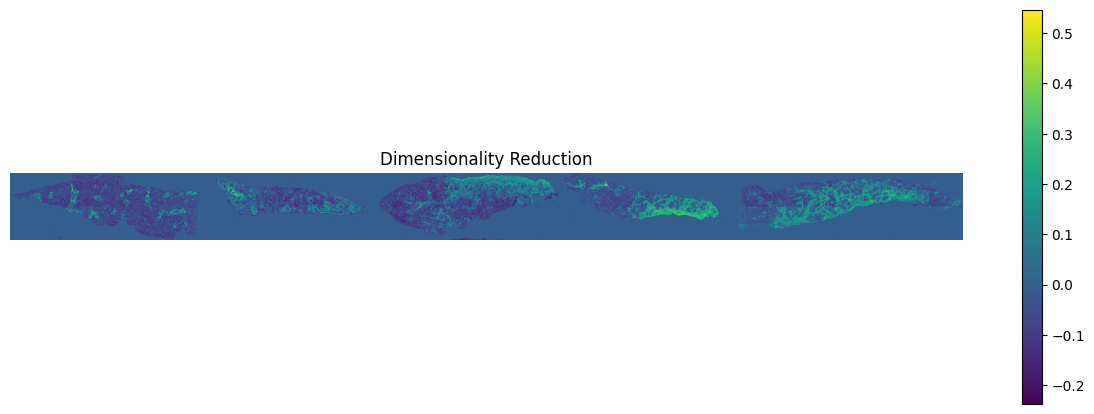

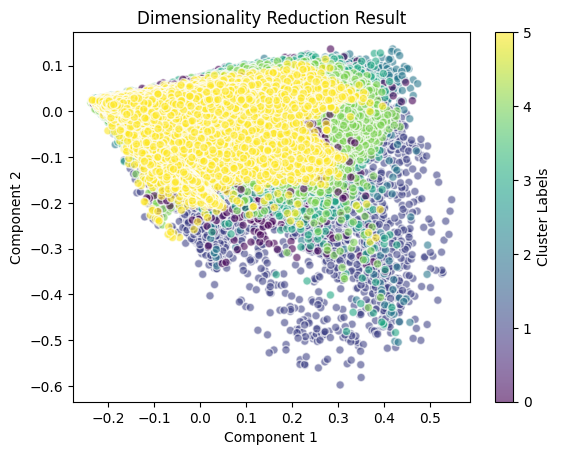

In [6]:
from specml.feature_engineering.dim_reduction import apply_pca, apply_umap
from specml.visualization.plotting import display_image, display_dim_reduction_as_image, plot_dim_reduction_result  #display_dim_reduction_as_interactive_plot

pca_result = apply_pca(combined_data, n_components=3)
display_dim_reduction_as_image(pca_result)

# Get the number of samples in the PCA/UMAP result
num_samples = pca_result.reduced_data.shape[0]

# Ensure labels match the number of samples in the reduced data
valid_labels = combined_data.labels[combined_data.mask.flatten()]  # Take only valid labels

# If the valid_labels length doesn't match num_samples, we need to ensure it does:
if valid_labels.shape[0] != num_samples:
    valid_labels = valid_labels[:num_samples]  # Adjust the labels to match the reduced data size

# Now plot the results
plot_dim_reduction_result(pca_result, labels=valid_labels)

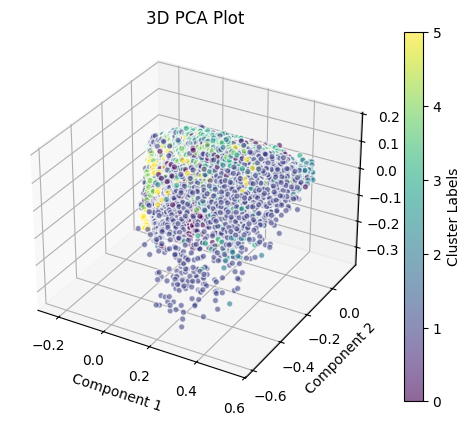

In [7]:
from specml.visualization.plotting import plot_3d_pca
plot_3d_pca(pca_result, labels=valid_labels)

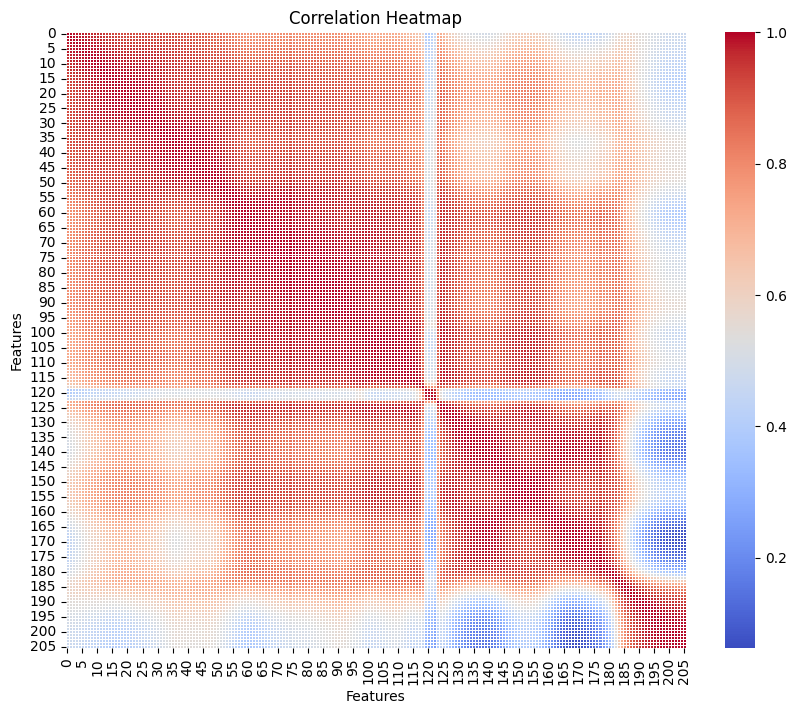

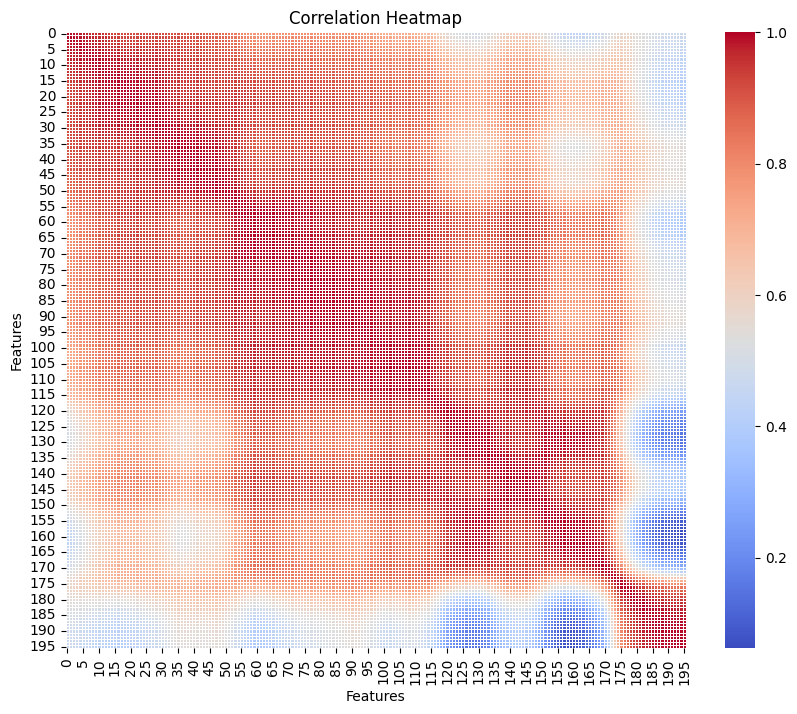

In [18]:
# test_data1.flatten().shape
from specml.visualization.plotting import plot_correlation_heatmap
plot_correlation_heatmap(combined_data.data)

filtered_wavenumbers = np.concatenate((combined_data.wavenumbers[:20], combined_data.wavenumbers[150:]))

filtered_data = np.concatenate((combined_data.data[:, :115], combined_data.data[:, 125:]), axis=1)
plot_correlation_heatmap(filtered_data)


(1412088, 20) (16,)


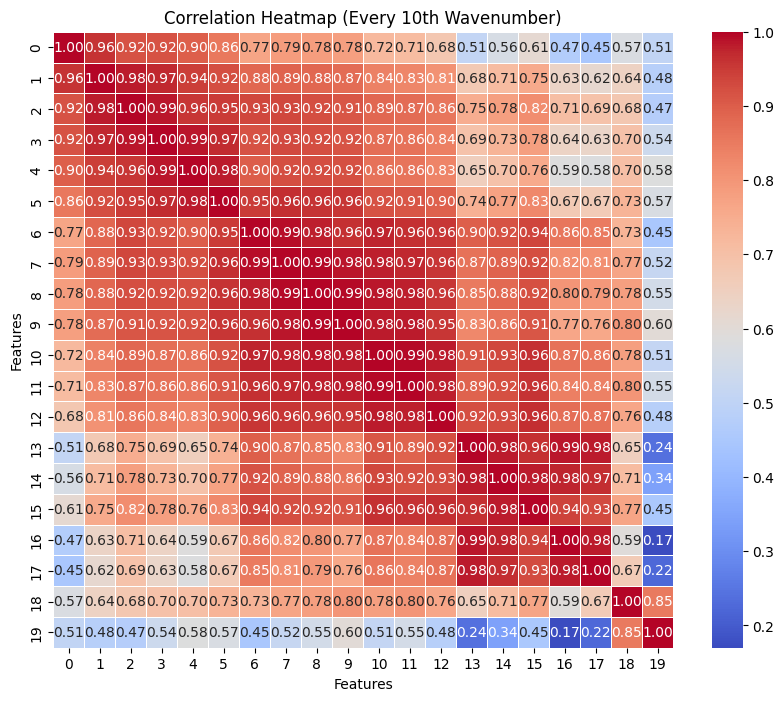

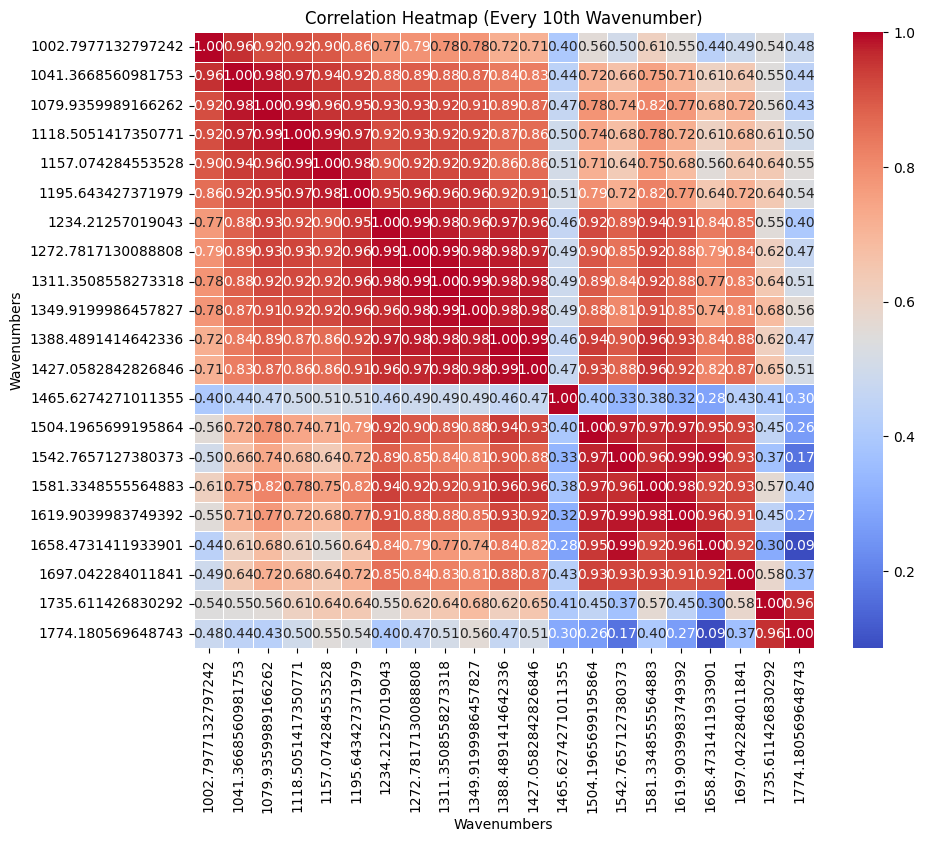

In [25]:
filtered_wavenumbers = np.concatenate((combined_data.wavenumbers[125:-1:10], combined_data.wavenumbers[125:-1:10]))
filtered_data = np.concatenate((combined_data.data[:, 0:115:10], combined_data.data[:, 125:-1:10]), axis=1)

print(filtered_data.shape, filtered_wavenumbers.shape)

plot_correlation_heatmap(filtered_data, title='Correlation Heatmap (Every 10th Wavenumber)', annot=True)
plot_correlation_heatmap(combined_data.data[:,::10], title='Correlation Heatmap (Every 10th Wavenumber)', wavenumbers=combined_data.wavenumbers[::10], annot=True)

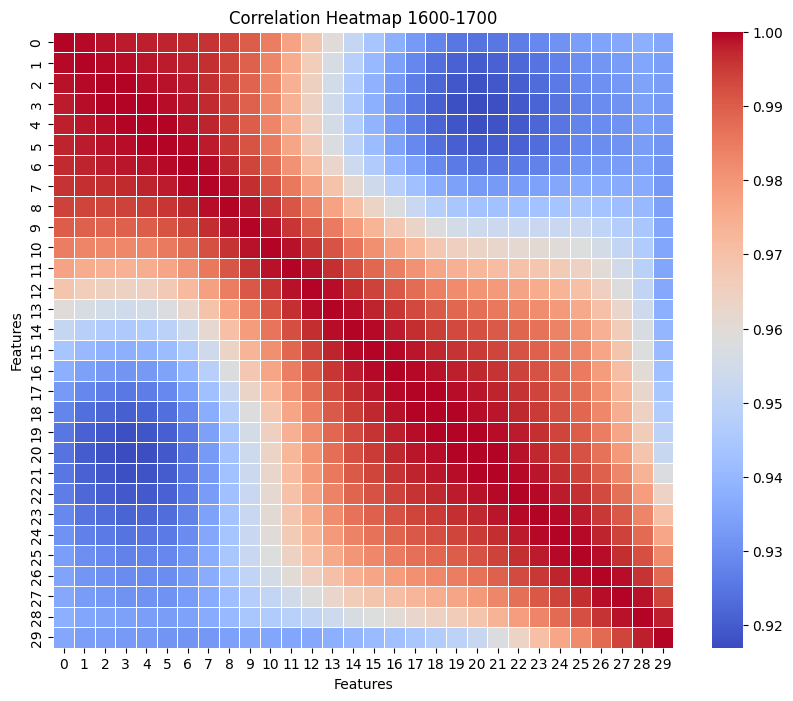

In [30]:
plot_correlation_heatmap(combined_data.data[:,150:180], title='Correlation Heatmap 1600-1700', annot=False)